# Download data and do train / test splits, if not already done
For the clustering methodology, refer to helper code (`biomanifolds/datasets/clustering.py`)
- MMSeqs2 easy clustering, 80% coverage
- then easy homology search to remove any remaining matches

In [1]:
from biomanifolds.datasets import swissprot

splits_dir = swissprot.swissprot_dir() / "splits"
if not (splits_dir / "splits.parquet").exists():
    swissprot.prepare_data()

# Sequence identity between train and test sets

shape: (3, 2)
┌─────────┬────────┐
│ split   ┆ count  │
│ ---     ┆ ---    │
│ str     ┆ u32    │
╞═════════╪════════╡
│ train   ┆ 411591 │
│ test    ┆ 86165  │
│ removed ┆ 51084  │
└─────────┴────────┘
max identity: 0.299


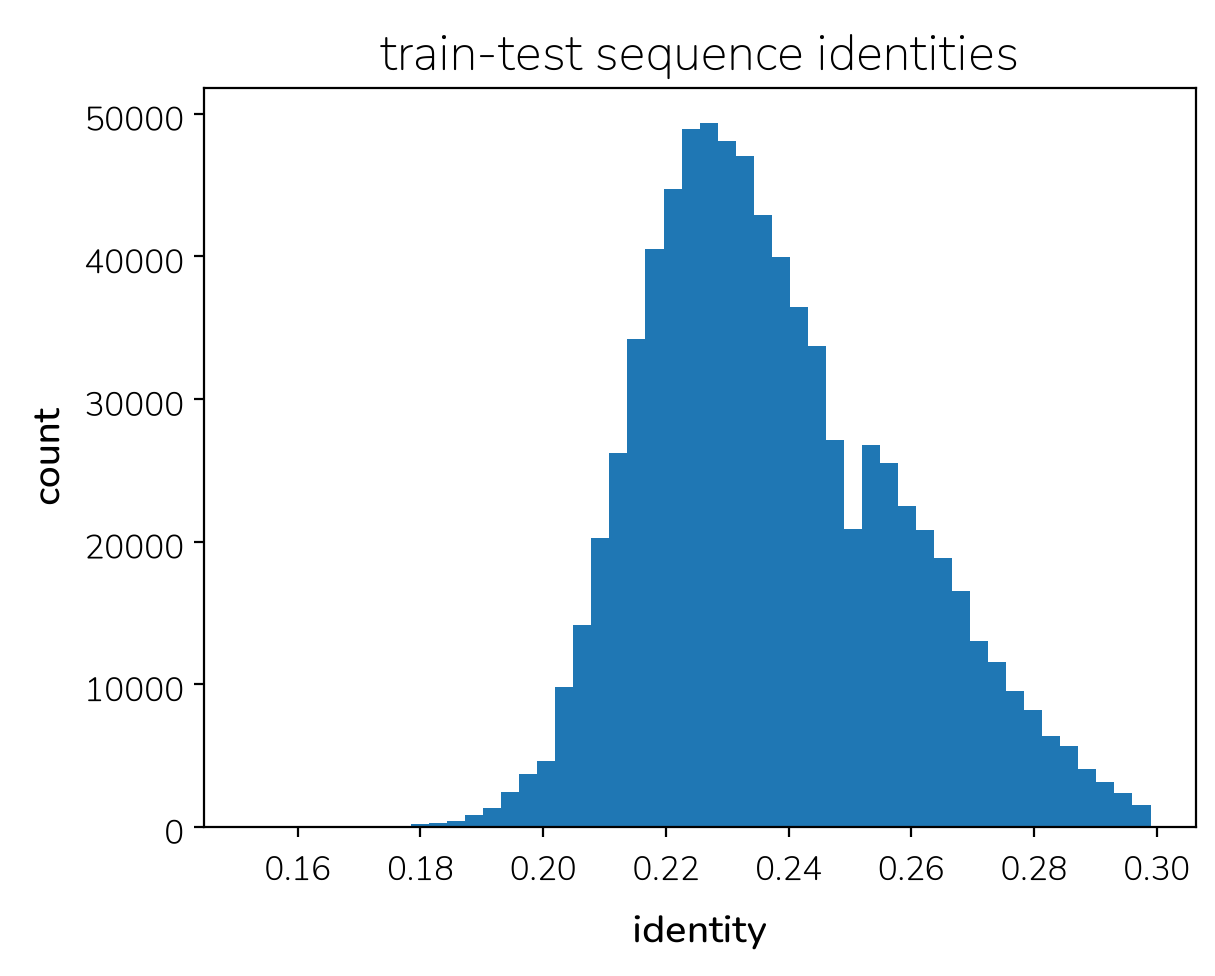

In [2]:
import matplotlib.pyplot as plt
import polars as pl

from biomanifolds import theme

theme.use()  # Nunito fonts and the project defaults

splits = pl.read_parquet(splits_dir / "splits.parquet")
print(splits["split"].value_counts())

hits = pl.read_csv(splits_dir / "test_vs_train.m8", separator="\t", has_header=False,
                   new_columns=["query", "target", "fident", "qcov", "tcov", "evalue"])
test = splits.filter(pl.col("split") == "test")["accession"]
identity = hits.filter(pl.col("query").is_in(test.implode()))["fident"]
print("max identity:", identity.max())

plt.hist(identity, bins=50)
plt.title("train-test sequence identities")
plt.xlabel("identity")
plt.ylabel("count")
plt.show()

# Protein statistics for our train / test split

Parsing FASTA: 0 lines [00:00, ? lines/s]

Parsing FASTA: 236628 lines [00:00, 2365932.53 lines/s]

Parsing FASTA: 483071 lines [00:00, 2423696.73 lines/s]

Parsing FASTA: 729652 lines [00:00, 2442910.27 lines/s]

Parsing FASTA: 984515 lines [00:00, 2484632.18 lines/s]

...

Parsing FASTA: 3549480 lines [00:01, 2541965.49 lines/s]

Parsing FASTA: 3814117 lines [00:01, 2573187.27 lines/s]

Parsing FASTA: 4071501 lines [00:01, 2567482.26 lines/s]

Parsing FASTA: 4328295 lines [00:01, 2461224.41 lines/s]

Parsing FASTA: 4347145 lines [00:01, 2515790.94 lines/s]

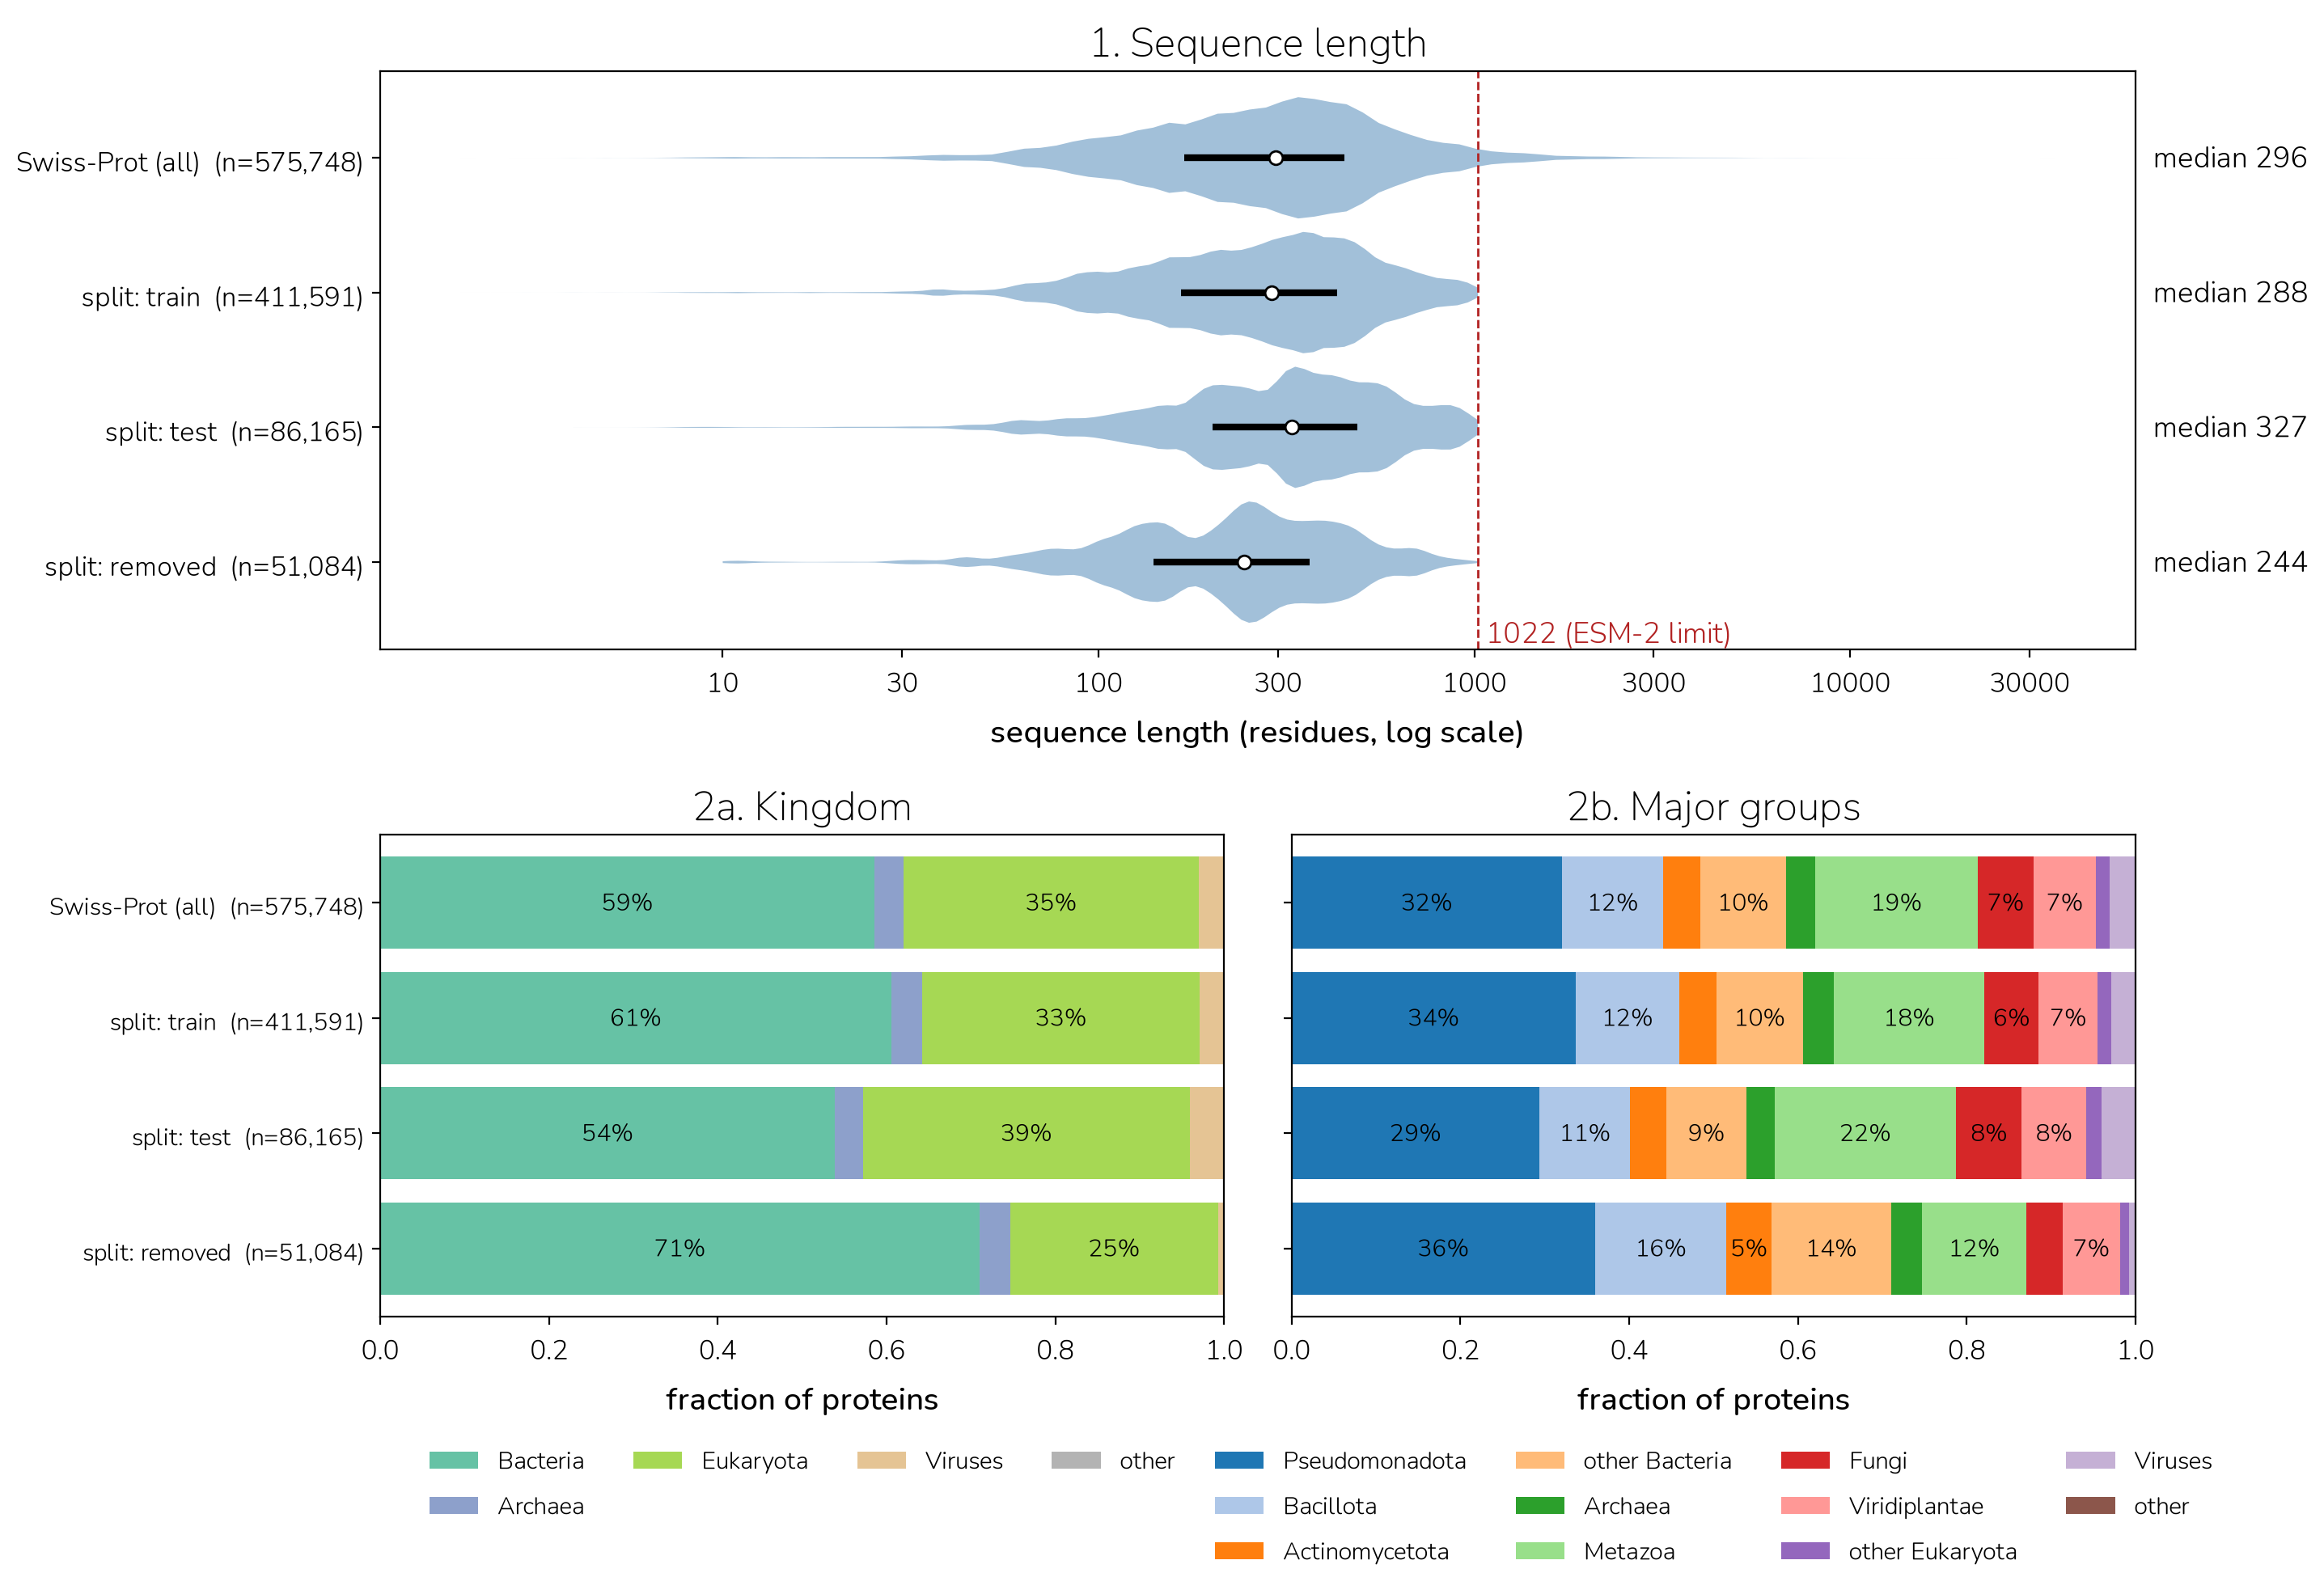

In [3]:
import numpy as np
from matplotlib.transforms import blended_transform_factory

raw = swissprot.read_fasta()
taxonomy = swissprot.read_taxonomy()
groups = {
    "Swiss-Prot (all)": raw.join(taxonomy, on="accession"),
    **{f"split: {name}": splits.filter(pl.col("split") == name).join(taxonomy, on="accession")
       for name in ["train", "test", "removed"]},
}
labels = [f"{name}  (n={len(df):,})" for name, df in groups.items()]

fig = plt.figure(figsize=(14, 10))
grid = fig.add_gridspec(2, 2, height_ratios=[1.2, 1], hspace=0.35, wspace=0.08)

# 1. Sequence length
ax = fig.add_subplot(grid[0, :])
y = np.arange(len(groups))[::-1]
log_lengths = [np.log10(df["length"].to_numpy()) for df in groups.values()]
parts = ax.violinplot(log_lengths, positions=y, orientation="horizontal", showextrema=False, widths=0.9)
for body in parts["bodies"]:
    body.set_facecolor("steelblue")
    body.set_alpha(0.5)
for yi, values in zip(y, log_lengths):
    q1, median, q3 = np.percentile(values, [25, 50, 75])
    ax.hlines(yi, q1, q3, color="black", lw=3)
    ax.scatter(median, yi, color="white", edgecolor="black", zorder=3)
    ax.text(1.01, yi, f"median {10**median:.0f}", va="center", transform=blended_transform_factory(ax.transAxes, ax.transData))
ax.axvline(np.log10(1022), color="firebrick", ls="--", lw=1)
ax.text(np.log10(1022) + 0.02, y[-1] - 0.6, "1022 (ESM-2 limit)", color="firebrick")
ticks = [10, 30, 100, 300, 1000, 3000, 10000, 30000]
ax.set_xticks(np.log10(ticks), [str(t) for t in ticks])
ax.set_yticks(y, labels)
ax.set_xlabel("sequence length (residues, log scale)")
ax.set_title("1. Sequence length")


def stacked_bars(ax, column, categories, colors, title):
    left = np.zeros(len(groups))
    for category, color in zip(categories, colors):
        fractions = np.array([(df[column] == category).mean() for df in groups.values()])
        ax.barh(y, fractions, left=left, color=color, label=category)
        for yi, l, f in zip(y, left, fractions):
            if f >= 0.05:
                ax.text(l + f / 2, yi, f"{f:.0%}", ha="center", va="center", fontsize="small")
        left += fractions
    ax.set_xlim(0, 1)
    ax.set_xlabel("fraction of proteins")
    ax.set_title(title)
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.22), ncol=4, frameon=False, fontsize="small")


# 2a. Kingdom
ax = fig.add_subplot(grid[1, 0])
kingdoms = ["Bacteria", "Archaea", "Eukaryota", "Viruses", "other"]
stacked_bars(ax, "kingdom", kingdoms, plt.cm.Set2([0, 2, 4, 6, 7]), "2a. Kingdom")
ax.set_yticks(y, labels, fontsize="small")

# 2b. Major groups
ax = fig.add_subplot(grid[1, 1])
major_groups = ["Pseudomonadota", "Bacillota", "Actinomycetota", "other Bacteria", "Archaea", "Metazoa",
                "Fungi", "Viridiplantae", "other Eukaryota", "Viruses", "other"]
stacked_bars(ax, "group", major_groups, plt.cm.tab20(range(11)), "2b. Major groups")
ax.set_yticks(y, [])

plt.show()

# Available labels

In [4]:
# Compute labels if not already available
from biomanifolds.labels import af2_structure_labels, label_metadata, sequence_labels, swissprot_labels

pl.Config(tbl_rows=-1, tbl_cols=-1, fmt_str_lengths=80, tbl_width_chars=300, tbl_hide_dataframe_shape=True)

for labels in [sequence_labels, swissprot_labels, af2_structure_labels]:
    if not labels.is_prepared():
        labels.prepare_data()

## 1. Labels contained in sequence

In [5]:
label_metadata.describe(sequence_labels.LABELS, sequence_labels.load_labels(), sequence_labels.load_protein_labels())

label,level,kind,dtype,source,mask,null_fraction,values,description
str,str,str,str,str,str,f64,str,str
"""aa""","""residue""","""categorical""","""String""","""sequence""","""""",0.0,"""{""label_type"": ""categorical"", ""n_categories"": 25, ""top"": [{""value"": ""L"", ""fracti…","""Amino acid (one-letter code)."""
"""rel_pos""","""residue""","""continuous""","""Float32""","""sequence""","""""",0.0,"""{""label_type"": ""continuous"", ""min"": 0.0, ""max"": 1.0, ""mean"": 0.5}""","""Relative position: 0 = N terminus, 1 = C terminus."""
"""dist_n""","""residue""","""count""","""Int32""","""sequence""","""""",0.0,"""{""label_type"": ""continuous"", ""min"": 0.0, ""max"": 1021.0, ""mean"": 223.7}""","""Residues to the N terminus."""
"""dist_c""","""residue""","""count""","""Int32""","""sequence""","""""",0.0,"""{""label_type"": ""continuous"", ""min"": 0.0, ""max"": 1021.0, ""mean"": 223.7}""","""Residues to the C terminus."""
"""length""","""protein""","""count""","""Int32""","""sequence""","""""",0.0,"""{""label_type"": ""continuous"", ""min"": 2.0, ""max"": 1022.0, ""mean"": 324.1}""","""Number of residues."""


## 2. Labels from Swiss-Prot annotations

In [6]:
label_metadata.describe(swissprot_labels.LABELS, swissprot_labels.load_labels(), swissprot_labels.load_protein_labels())

label,level,kind,dtype,source,mask,null_fraction,values,description
str,str,str,str,str,str,f64,str,str
"""in_signal""","""residue""","""binary""","""Boolean""","""swissprot""","""""",0.0,"""{""label_type"": ""binary"", ""true_fraction"": 0.00549}""","""In a signal peptide."""
"""in_transit""","""residue""","""binary""","""Boolean""","""swissprot""","""""",0.0,"""{""label_type"": ""binary"", ""true_fraction"": 0.001898}""","""In a transit peptide."""
"""in_propep""","""residue""","""binary""","""Boolean""","""swissprot""","""""",0.0,"""{""label_type"": ""binary"", ""true_fraction"": 0.003024}""","""In a propeptide."""
"""in_peptide""","""residue""","""binary""","""Boolean""","""swissprot""","""""",0.0,"""{""label_type"": ""binary"", ""true_fraction"": 0.001341}""","""In a released active peptide."""
"""in_transmem""","""residue""","""binary""","""Boolean""","""swissprot""","""""",0.0,"""{""label_type"": ""binary"", ""true_fraction"": 0.04253}""","""In a transmembrane segment."""
"""in_intramem""","""residue""","""binary""","""Boolean""","""swissprot""","""""",0.0,"""{""label_type"": ""binary"", ""true_fraction"": 0.0002117}""","""In a segment inside the membrane that does not cross it."""
"""in_disordered""","""residue""","""binary""","""Boolean""","""swissprot""","""""",0.0,"""{""label_type"": ""binary"", ""true_fraction"": 0.04482}""","""In a disordered region."""
"""in_coiled""","""residue""","""binary""","""Boolean""","""swissprot""","""""",0.0,"""{""label_type"": ""binary"", ""true_fraction"": 0.006531}""","""In a coiled coil."""
"""in_compbias""","""residue""","""binary""","""Boolean""","""swissprot""","""""",0.0,"""{""label_type"": ""binary"", ""true_fraction"": 0.01884}""","""In a region of compositional bias."""


## 3. Labels from AlphaFold DB structures
Source `afdb`: read from the model. Source `computed`: calculated from the model coordinates. Mask `residue`: null where pLDDT < 70; mask `element`: null for the whole secondary-structure element.

In [7]:
label_metadata.describe(af2_structure_labels.LABELS, af2_structure_labels.load_labels())

label,level,kind,dtype,source,mask,null_fraction,values,description
str,str,str,str,str,str,f64,str,str
"""plddt""","""residue""","""continuous""","""Float32""","""afdb""","""""",0.0,"""{""label_type"": ""continuous"", ""min"": 1.37, ""max"": 99.0, ""mean"": 87.11}""","""AlphaFold per-residue confidence (0-100)."""
"""confident""","""residue""","""binary""","""Boolean""","""afdb""","""""",0.0,"""{""label_type"": ""binary"", ""true_fraction"": 0.8618}""","""pLDDT >= PLDDT_MIN."""
"""ss3""","""residue""","""categorical""","""String""","""computed""","""residue""",0.1382,"""{""label_type"": ""categorical"", ""n_categories"": 3, ""top"": [{""value"": ""-"", ""fractio…","""Secondary structure: H, E or -."""
"""seg_len""","""residue""","""count""","""Int32""","""computed""","""element""",0.2329,"""{""label_type"": ""continuous"", ""min"": 1.0, ""max"": 283.0, ""mean"": 14.64}""","""Length of the secondary-structure element that contains the residue."""
"""pos_in_seg""","""residue""","""count""","""Int32""","""computed""","""element""",0.2329,"""{""label_type"": ""continuous"", ""min"": 0.0, ""max"": 282.0, ""mean"": 6.819}""","""0-based position of the residue in its secondary-structure element."""
"""seg_frac""","""residue""","""continuous""","""Float32""","""computed""","""element""",0.2329,"""{""label_type"": ""continuous"", ""min"": 0.0, ""max"": 1.0, ""mean"": 0.5}""","""Relative position in the element: 0 = first residue, 1 = last, 0.5 for one resid…"
"""n_cap""","""residue""","""binary""","""Boolean""","""computed""","""element""",0.2329,"""{""label_type"": ""binary"", ""true_fraction"": 0.02859}""","""The residue just before a helix."""
"""c_cap""","""residue""","""binary""","""Boolean""","""computed""","""element""",0.2329,"""{""label_type"": ""binary"", ""true_fraction"": 0.02836}""","""The residue just after a helix."""
"""helix_face""","""residue""","""angle""","""Float32""","""computed""","""element""",0.6926,"""{""label_type"": ""periodic"", ""min"": -180.0, ""max"": 180.0, ""circular_mean"": 80.55}""","""Angle of the residue around the local helix axis; 0 = pointing toward the protei…"
